06 — Analyse critique et responsabilité (Partie 6)

1. **Explicabilité** : cartes Grad-CAM sur des prédictions correctes et incorrectes du meilleur classifieur (choisi sur la validation au notebook 02). Le modèle regarde-t-il la **lésion** ou le **fond** ?
2. **Analyse d'erreurs** : erreurs du meilleur classifieur (ResNet-50), puis au moins 10 erreurs du **modèle recommandé pour le smartphone** (MobileNetV3-Large, partie 2), celui qui serait réellement déployé.
3. à 5. Questions guidées : du laboratoire au champ, enjeux éthiques et sociaux, limites et perspectives.

**Protocole :** les prédictions sur le test ont été enregistrées lors de l'évaluation unique du notebook 02 (`test_predictions.csv`). Ici, on ne fait qu'**analyser** ces erreurs : aucun modèle, hyperparamètre ou seuil n'est modifié en conséquence. Aucun modèle n'est réévalué sur le test. Si le modèle recommandé fait moins de 10 erreurs sur le test, on complète avec ses erreurs sur la **validation** (prédictions calculées ici, ce qui est autorisé), signalées comme telles. Grad-CAM refait un passage avant/arrière sur ces images, uniquement pour l'explication.



In [ ]:
# === Configuration (Colab, Kaggle ou local) ===
ALLOW_CPU = True   # True seulement pour les notebooks sans entraînement (00 et 06)
REPO_URL = "https://github.com/fayelise/diagnoculture.git"   # utilisé sur Kaggle uniquement

import os, sys, subprocess
from pathlib import Path

# 1. Environnement. Colab est testé AVANT Kaggle : sur Colab, kagglehub peut créer /kaggle/input.
IN_COLAB = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ
IN_KAGGLE = not IN_COLAB and "KAGGLE_KERNEL_RUN_TYPE" in os.environ

if IN_COLAB:
    # Projet sur Google Drive : résultats et checkpoints survivent aux déconnexions
    from google.colab import drive, userdata
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/diagnoculture")
    os.environ["DIAGNO_CACHE"] = "/content/cache"   # cache d'images sur le disque local de Colab (rapide)
    for name in ("KAGGLE_API_TOKEN", "KAGGLE_USERNAME", "KAGGLE_KEY"):   # jeton Kaggle (Secrets Colab)
        try:
            os.environ[name] = userdata.get(name)
        except Exception:
            pass
elif IN_KAGGLE:
    # Code cloné depuis GitHub ; résultats du notebook précédent (ajouté en Input) recopiés
    # dans /kaggle/working : l'Output de ce notebook contiendra donc toute la chaîne.
    import shutil
    ROOT = Path("/kaggle/working/diagnoculture")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, str(ROOT)], check=True)
    for inp in Path("/kaggle/input").iterdir():
        for prev in (inp / "results", inp / "diagnoculture" / "results"):
            if (prev / "00_split").is_dir():
                shutil.copytree(prev, ROOT / "results", dirs_exist_ok=True)
else:
    # Local : notebook lancé depuis notebooks/ ou depuis la racine du dépôt
    ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent

assert (ROOT / "src" / "utils.py").exists(), f"Projet introuvable dans {ROOT} (voir README, section Installation)"
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

# 2. Paquets absents des images Colab / Kaggle (en local : pip install -r requirements.txt)
if IN_COLAB or IN_KAGGLE:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "torchinfo==1.8.0", "ImageHash==4.3.2",
                    "grad-cam==1.5.7", "onnx==1.23.2", "onnxruntime==1.29.0",
                    "umap-learn==0.5.12", "kagglehub==1.0.2"], check=True)

# 3. Configuration du projet
from src.utils import load_config, resolve_paths, set_seed, ensure_data, get_device, machine_info, TestGuard
cfg = load_config()
set_seed(cfg["seed"])
paths = resolve_paths(cfg)
DATA_ROOT = ensure_data(cfg)          # télécharge PlantVillage au 1er lancement de la session (hors Kaggle)
DEVICE = get_device()
guard = TestGuard(paths["results"])   # le test ne sert qu'une fois par modèle final
FORCE_TEST_RERUN = False              # True uniquement pour ré-exécuter à l'identique après une coupure
print("Projet :", ROOT, "| données :", DATA_ROOT, "| device :", DEVICE)
print(machine_info())

# 4. Garde-fou GPU : sur CPU, chaque epoch est 40 à 80 fois plus lente et le budget train.max_minutes
#    coupe les entraînements après 1 à 4 epochs (cause des résultats invalides de la 1re exécution).
#    DIAGNO_ALLOW_CPU=1 sert uniquement au test rapide du pipeline (README).
if DEVICE.type != "cuda" and not (ALLOW_CPU or os.environ.get("DIAGNO_ALLOW_CPU") == "1"):
    raise RuntimeError("Pas de GPU : Exécution → Modifier le type d'exécution → T4 GPU "
                       "(Kaggle : Session options → Accelerator → GPU T4).")

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from src.datasets import (CLASSES, IMAGENET_MEAN, IMAGENET_STD, TensorImageDataset, build_transform,
                          get_split_tensors, make_loader)
from src.gradcam import GradCAM, cam_on_leaf_ratio, leaf_mask, overlay
from src.models import TransferModel
from src.train import load_best, predict_logits
from src.utils import load_json, save_json

P6 = cfg["part6"]
OUT = paths["results"] / "06_analysis"
OUT.mkdir(parents=True, exist_ok=True)
best = load_json(paths["results"] / "02_transfer" / "best_model.json")
exp = paths["results"] / best["exp_dir"]
model = load_best(TransferModel(best["backbone"], len(CLASSES), pretrained=False), exp)
SIZE = best["img_size"]

df_test, x_test = get_split_tensors(paths, DATA_ROOT, SIZE, splits=("test",))["test"]

def annotate(p, split):
    """Ajoute noms de classes, justesse et jeu d'origine à un tableau (y_true, y_pred, confidence)."""
    p["class_true"] = np.array(CLASSES)[p["y_true"]]
    p["class_pred"] = np.array(CLASSES)[p["y_pred"]]
    p["correct"] = p["y_true"] == p["y_pred"]
    p["split"] = split
    return p

def saved_test_predictions(exp_dir):
    """Prédictions sur le test enregistrées lors de l'évaluation UNIQUE du notebook 02 (aucune réévaluation)."""
    p = pd.read_csv(exp_dir / "test_predictions.csv")
    assert (p["y_true"].to_numpy() == df_test["label"].to_numpy()).all(), "Ordre du test incohérent avec les prédictions enregistrées"
    return annotate(p, "test")

pred = saved_test_predictions(exp)
tf = build_transform(False, IMAGENET_MEAN, IMAGENET_STD)
cam = GradCAM(model, model.gradcam_layer())
print(f"Meilleur classifieur : {best['backbone']} ({best['strategy']}) — {(~pred['correct']).sum()} erreurs sur {len(pred)} images de test")

def cams_for(indices):
    """Cartes Grad-CAM pour la classe PRÉDITE (ce qui a motivé la décision du modèle)."""
    x = torch.stack([tf(x_test[i]) for i in indices]).to(DEVICE)
    return cam(x)

def raw(i):
    return x_test[i].permute(1, 2, 0).numpy()

0. Vérification de notre implémentation de Grad-CAM

`src/gradcam.py` implémente Grad-CAM explicitement (poids $\alpha_k$ = moyenne spatiale de $\partial y_c/\partial A_k$, carte = ReLU$(\sum_k \alpha_k A_k)$) pour pouvoir le justifier à l'oral. On vérifie qu'elle coïncide avec la bibliothèque `pytorch-grad-cam` (corrélation proche de 1).

In [3]:
from pytorch_grad_cam import GradCAM as LibGradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

ids = list(range(min(4, len(pred))))
ours = cams_for(ids)
x = torch.stack([tf(x_test[i]) for i in ids]).to(DEVICE)
with LibGradCAM(model=model, target_layers=[model.gradcam_layer()]) as lib:
    theirs = lib(input_tensor=x, targets=[ClassifierOutputTarget(int(c)) for c in pred.loc[ids, "y_pred"]])
corr = [np.corrcoef(a.ravel(), b.ravel())[0, 1] for a, b in zip(ours, theirs)]
print("Corrélation avec pytorch-grad-cam :", np.round(corr, 4))

Corrélation avec pytorch-grad-cam : [1. 1. 1. 1.]


# 1. Grad-CAM : prédictions correctes (une par classe)

In [ ]:
def grid(images, infos, title, fname, cam_obj, ncol=5):
    """Images (uint8) et cartes Grad-CAM de `cam_obj` ; `infos` : une ligne par image (vrai, prédit, confiance, jeu)."""
    maps = cam_obj(torch.stack([tf(im) for im in images]).to(DEVICE))
    nrow = int(np.ceil(len(images) / ncol))
    fig, axes = plt.subplots(2 * nrow, ncol, figsize=(2.6 * ncol, 5.4 * nrow), squeeze=False)
    for k, (im, (_, p), m) in enumerate(zip(images, infos.iterrows(), maps)):
        r, c = 2 * (k // ncol), k % ncol
        rgb = im.permute(1, 2, 0).numpy()
        axes[r, c].imshow(rgb)
        axes[r, c].set_title(f"[{p['split']}] vrai : {p['class_true'][:16]}\nprédit : {p['class_pred'][:16]} ({p['confidence']:.2f})",
                             fontsize=7, color="green" if p["correct"] else "red")
        axes[r + 1, c].imshow(overlay(rgb, m))
    for a in axes.ravel():
        a.axis("off")
    fig.suptitle(title, fontsize=10)
    fig.tight_layout()
    fig.savefig(OUT / fname, dpi=130)
    return maps

rng = np.random.default_rng(cfg["seed"])
correct_idx = [int(rng.choice(pred.index[(pred["correct"]) & (pred["y_true"] == k)]))
               for k in range(len(CLASSES)) if ((pred["correct"]) & (pred["y_true"] == k)).any()]
_ = grid([x_test[i] for i in correct_idx], pred.loc[correct_idx], "Grad-CAM — prédictions CORRECTES (une par classe)",
         "gradcam_correct.png", cam)

2. Grad-CAM : erreurs du meilleur classifieur

Les erreurs sont triées par **confiance décroissante** : les erreurs commises « avec aplomb » sont les plus dangereuses pour un maraîcher, et exactement ce que la partie 4 cherche à rejeter. Le meilleur classifieur (ResNet-50) fait très peu d'erreurs : l'analyse d'au moins 10 erreurs porte donc sur le modèle recommandé (section 2 bis).

In [ ]:
err = pred[~pred["correct"]].sort_values("confidence", ascending=False)
err_idx = err.index[:P6["n_errors"]].tolist()
if len(err_idx):
    _ = grid([x_test[i] for i in err_idx], err.loc[err_idx],
             f"Grad-CAM — {best['backbone']} : {len(err_idx)} ERREURS (les plus confiantes d'abord)", "gradcam_errors.png", cam)
print("Paires de confusion les plus fréquentes :")
display(err.groupby(["class_true", "class_pred"]).size().sort_values(ascending=False).head(10).rename("n"))

# 2 bis. Erreurs du modèle recommandé pour le smartphone (au moins 10)

Le modèle **déployé** serait MobileNetV3-Large (fine-tuning complet), recommandé en partie 2 pour son compromis précision / taille / latence : ce sont **ses** erreurs qu'un maraîcher rencontrerait.

- Erreurs de **test** : relues dans `test_predictions.csv` (évaluation unique du notebook 02, aucune réévaluation).
- S'il y en a moins de `part6.n_errors`, on complète avec des erreurs de **validation** : prédictions calculées ici, ce qui est autorisé (aucun choix n'en découle). Le jeu d'origine est indiqué entre crochets au-dessus de chaque image.

In [ ]:
RECO = {"backbone": "mobilenet_v3_large", "exp_dir": "02_transfer/mobilenet_v3_large_full"}   # recommandation de la partie 2
exp_reco = paths["results"] / RECO["exp_dir"]
model_reco = load_best(TransferModel(RECO["backbone"], len(CLASSES), pretrained=False), exp_reco)
cam_reco = GradCAM(model_reco, model_reco.gradcam_layer())

pred_reco = saved_test_predictions(exp_reco)
err_reco = pred_reco[~pred_reco["correct"]].sort_values("confidence", ascending=False)
images = [x_test[i] for i in err_reco.index]
n_missing = P6["n_errors"] - len(err_reco)
if n_missing > 0:
    # Complément : erreurs de VALIDATION (prédictions calculées ici, le test n'est pas réutilisé)
    df_val, x_val = get_split_tensors(paths, DATA_ROOT, SIZE, splits=("val",))["val"]
    # num_workers = 0 : images déjà en mémoire, transformation légère (les workers n'apporteraient rien)
    val_loader = make_loader(TensorImageDataset(x_val, df_val["label"], tf), 64, False, num_workers=0)
    logits, y = predict_logits(model_reco, val_loader, DEVICE)
    prob = torch.softmax(logits, 1)
    pred_val = annotate(pd.DataFrame({"y_true": y.numpy(), "y_pred": prob.argmax(1).numpy(),
                                      "confidence": prob.max(1).values.numpy()}), "val")
    err_val = pred_val[~pred_val["correct"]].sort_values("confidence", ascending=False).head(n_missing)
    images += [x_val[i] for i in err_val.index]
    err_reco = pd.concat([err_reco, err_val])
print(f"{RECO['backbone']} : {(err_reco['split'] == 'test').sum()} erreurs de test "
      f"+ {(err_reco['split'] == 'val').sum()} erreurs de validation (complément)")

_ = grid(images, err_reco, f"Grad-CAM — {RECO['backbone']} (modèle recommandé) : {len(images)} ERREURS",
         "gradcam_errors_recommended.png", cam_reco)
cam_reco.remove()
display(err_reco[["split", "class_true", "class_pred", "confidence"]].reset_index(drop=True).round(3))

3. Le modèle regarde-t-il la feuille ou le fond ? (mesure du *shortcut learning*)

Le fond PlantVillage est gris et peu saturé : un masque approximatif de la feuille s'obtient en seuillant la **saturation** (méthode d'Otsu). On mesure la **part de la masse Grad-CAM située sur la feuille**. Une part faible signale que la décision s'appuie sur le fond (ombres, bords, éclairage propre à une session de prise de vue) : risque de *shortcut learning*.

         leaf_fraction  cam_on_leaf
correct                            
False            0.245        0.658
True             0.353        0.690


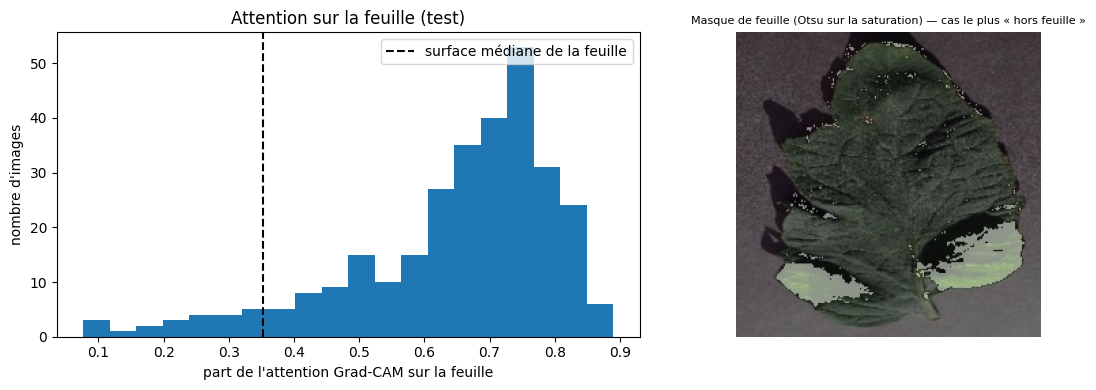

In [6]:
sample = list(rng.choice(pred.index, min(300, len(pred)), replace=False))
ratios = []
for s in range(0, len(sample), 32):
    chunk = sample[s:s + 32]
    for i, m in zip(chunk, cams_for(chunk)):
        ratios.append({"idx": i, "correct": bool(pred.loc[i, "correct"]), "leaf_fraction": leaf_mask(raw(i)).mean(),
                       "cam_on_leaf": cam_on_leaf_ratio(m, leaf_mask(raw(i)))})
ratios = pd.DataFrame(ratios)
ratios.to_csv(OUT / "cam_on_leaf.csv", index=False)
print(ratios.groupby("correct")[["leaf_fraction", "cam_on_leaf"]].median().round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(ratios["cam_on_leaf"], bins=20, color="tab:blue")
axes[0].axvline(ratios["leaf_fraction"].median(), color="k", ls="--", label="surface médiane de la feuille")
axes[0].set(xlabel="part de l'attention Grad-CAM sur la feuille", ylabel="nombre d'images", title="Attention sur la feuille (test)")
axes[0].legend()
i0 = int(ratios.sort_values("cam_on_leaf").iloc[0]["idx"])   # image où l'attention est la plus « hors feuille »
axes[1].imshow(np.dstack([leaf_mask(raw(i0))] * 3) * 0.5 + raw(i0) / 255 * 0.5)
axes[1].set_title("Masque de feuille (Otsu sur la saturation) — cas le plus « hors feuille »", fontsize=8)
axes[1].axis("off")
fig.tight_layout()
fig.savefig(OUT / "cam_on_leaf.png", dpi=150)
cam.remove()

**Lecture :** si l'attention était répartie au hasard, sa part sur la feuille vaudrait la surface de la feuille (ligne pointillée). Nettement au-dessus → le modèle se concentre sur la feuille. Examiner à la main les images où la part est faible. Limite de la mesure : le masque par saturation est approximatif (feuilles jaunies peu saturées, ombres).

---
## 4. Analyse d'erreurs — à rédiger (≥ 10 images : grille du modèle recommandé, section 2 bis)

Pour chaque **famille d'erreurs**, proposer une explication. Pistes fréquentes :
- **maladies à taches nécrotiques ressemblantes** (*Early_blight* ↔ *Target_Spot* ↔ *Septoria*) : symptômes proches à 224 px, différences de texture fines (anneaux concentriques, halo) ;
- **stade précoce / symptômes peu visibles** confondus avec *healthy* ;
- **co-infection ou étiquette douteuse** (le jeu PlantVillage contient du bruit d'étiquetage) ;
- **attention sur le fond ou le bord** (cartes Grad-CAM hors lésion) → indice de *shortcut learning* ;
- **images atypiques** (feuille partielle, flou, éclairage).

| # | Jeu | Vrai | Prédit | Confiance | Ce que montre Grad-CAM | Famille / explication |
|:--|:----|:-----|:-------|:----------|:-----------------------|:----------------------|
| 1 |     |      |        |           |                        |                       |
| … |     |      |        |           |                        |                       |

## 5. Du laboratoire au champ (Niayes, vallée du fleuve)
- Quelles différences entre PlantVillage et une photo prise au smartphone dans un champ ? *(éclairage solaire direct et ombres, fond de sol/adventices/autres feuilles, plusieurs feuilles par image, résolution et flou de bougé, poussière, variétés locales, stades phénologiques, symptômes mixtes, maladies absentes de PlantVillage)*
- Quelles conséquences sur votre modèle (cf. Grad-CAM, résultats OOD du notebook 04) ?
- **Quelles données collecteriez-vous ?** Protocole : photos de terrain étiquetées par des agents agricoles / phytopathologistes, plusieurs saisons, sites (Niayes, vallée), variétés, smartphones d'entrée de gamme ; images « négatives » (non-tomate) ; consentement des producteurs ; découpage par **parcelle** (pas par image) pour éviter la fuite.

## 6. Enjeux éthiques et sociaux
- **Faux négatif** (maladie non détectée) : propagation, perte de récolte, revenu du maraîcher.
- **Faux positif** (maladie inventée) : traitement phytosanitaire inutile : coût, santé de l'applicateur, environnement, résistances.
- Pourquoi le rejet « inconnu » est une **protection** et pas un échec ; qui décide ensuite ? → **place de l'agent agricole** : outil d'aide, décision humaine, remontée des cas « inconnu » pour enrichir le système.
- **Accessibilité** : fonctionnement **hors-ligne**, smartphone modeste (taille/latence mesurées au notebook 02), langues locales (wolof, pulaar…), interface pour utilisateurs peu alphabétisés, coût des données mobiles.
- Données des producteurs : propriété, consentement, géolocalisation sensible.

## 7. Limites et perspectives du prototype
- Données de laboratoire uniquement ; un seul M en leave-one-class-out ; seuils réglés sur une validation de même distribution que le test.
- Perspectives : données de terrain, segmentation de la feuille avant classification, augmentation de fond (*background replacement*), calibration des probabilités (*temperature scaling*), quantification statique et test sur un vrai téléphone, apprentissage actif à partir des rejets.